In [1]:
import os
import librosa
import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
BASE_FOLDER = "./Artists/Rapper/"
audio_file = os.path.join(BASE_FOLDER, "Eminem-Godzilla-ft-Juice-WRLD-(HipHopKit.com).mp3")

In [3]:
ipd.Audio(audio_file)

In [8]:
signal, sr = librosa.load(audio_file)
print(signal)
print(sr)

[0. 0. 0. ... 0. 0. 0.]
22050


### **EXTRACTING MFCC**

In [9]:
mfccs:np.ndarray[13,9161] = librosa.feature.mfcc(y=signal, n_mfcc=13, sr=sr)
mfccs.shape

(13, 9161)

### **VISUALIZING MFCC**

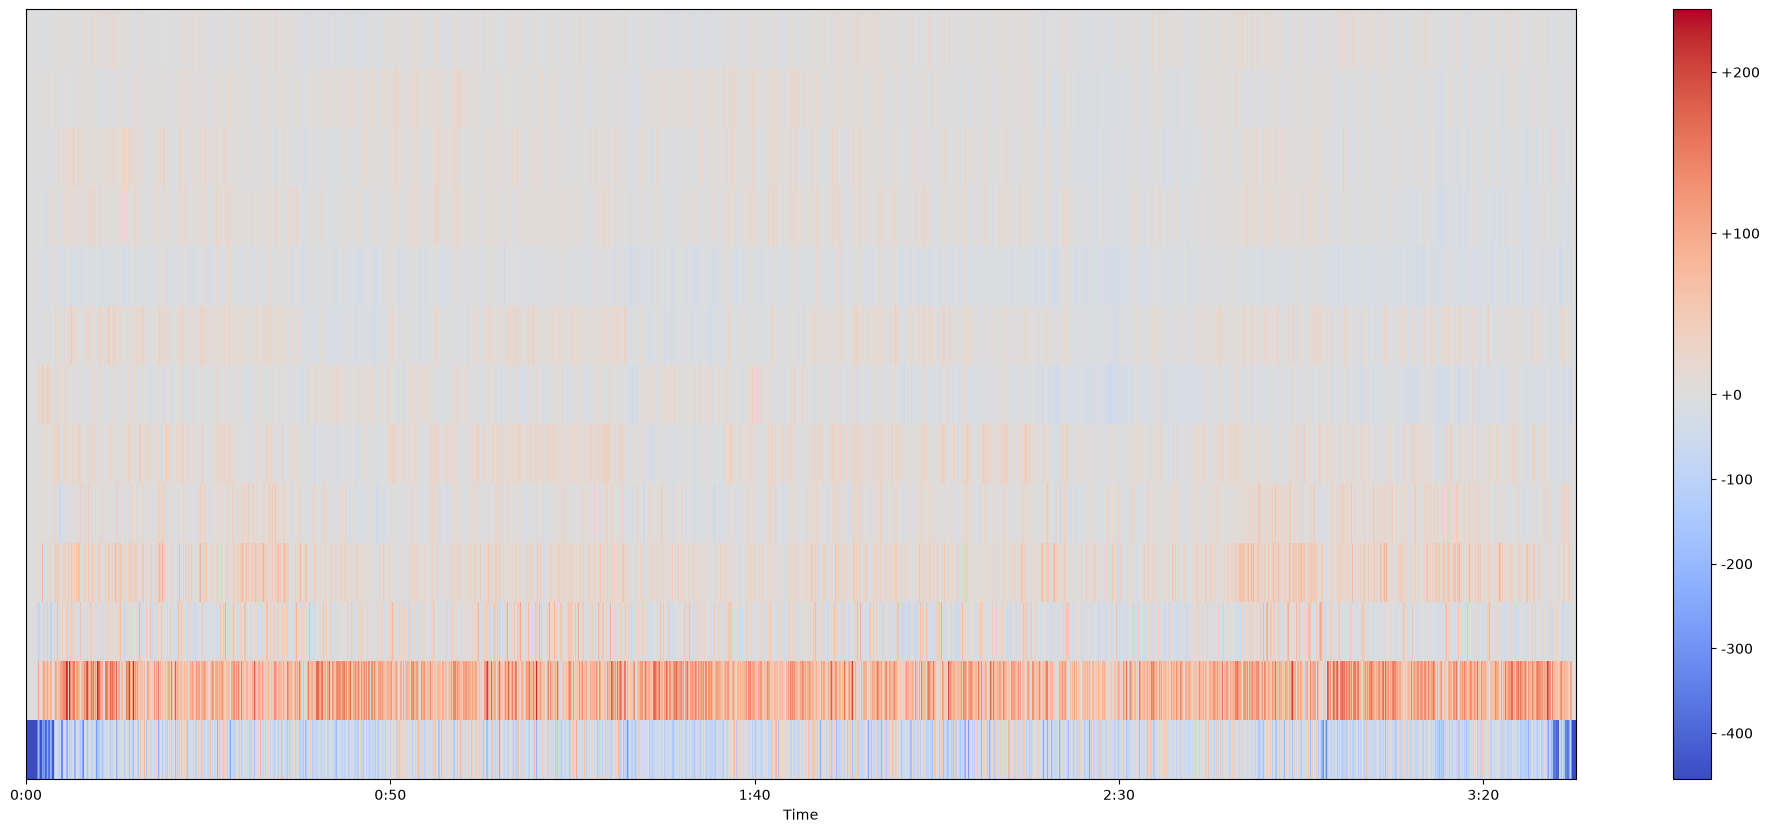

In [6]:
plt.figure(figsize=(25, 10))
librosa.display.specshow(mfccs, 
    x_axis="time", 
    sr=sr)
plt.colorbar(format="%+2.f")
plt.show()

##### **NOTES** 
- output is a 2D matrix, not a vector. It has shape (n_mfcc, n_frames)
- if you look closely, you can notice the 13 rows which coensides with your n_mfcc(number of MFCCs)
    - Row 0 is roughly the overall energy/loudness. 
    - Row 1 describes the broad spectral tilt (energy in low vs. high frequencies). Higher rows describe progressively finer detail in the spectral shape.
- the first 13 coefficients of a n_mfcc=20 **IS THE SAME** as the first 13 coefficients of a n_mfcc=13
    - 13 is just the standard for some reason
    - 20 is the second most common standard
    - The first 13 coefficients often preserve much of this information 
        - Coefficients 13 through 19 add finer detail. 
        - This detail can help some tasks, but it can also represent noise or recording conditions
        - (need source for this).
- generally never pass the whole matrix for classical ML
    - Mean and standard deviation of each coefficient across frames (e.g., 13 MFCCs gives 26 features)
    - Often add delta and delta-delta (first and second derivatives) before summarizing, giving 78 features
    - Sometimes min, max, skewness or kurtosis too
- only CNNs, RNNs/LSTMs, or transformers use the entire MFCC matrix



#### ***EXTRACTING MFCC DATA FOR ML***

In [13]:
import pandas as pd

feats = {}
for i in range(13):
    feats[f"mfcc{i+1}_mean"] = mfccs[i].mean()
    feats[f"mfcc{i+1}_std"] = mfccs[i].std()

    # Other common features
    feats["zcr_mean"] = librosa.feature.zero_crossing_rate(signal).mean()
    feats["centroid_mean"] = librosa.feature.spectral_centroid(y=signal, sr=sr).mean()
    feats["rolloff_mean"] = librosa.feature.spectral_rolloff(y=signal, sr=sr).mean()
    feats["rms_mean"] = librosa.feature.rms(y=signal).mean()

(1, 31)


,file,mfcc1_mean,mfcc1_std,zcr_mean,centroid_mean,rolloff_mean,rms_mean,mfcc2_mean,mfcc2_std,mfcc3_mean,...,mfcc9_mean,mfcc9_std,mfcc10_mean,mfcc10_std,mfcc11_mean,mfcc11_std,mfcc12_mean,mfcc12_std,mfcc13_mean,mfcc13_std
0,./Artists/Rapper/Eminem-Godzilla-ft-Juice-WRLD...,-54.020779,84.156471,0.113495,2572.596331,5252.738255,0.249244,83.145653,43.868065,1.076324,...,-10.899968,12.347642,1.509093,12.535928,0.665724,12.134501,1.722291,10.242971,0.257896,9.785506


In [ ]:

df = pd.DataFrame([feats])
df.insert(0, "file", audio_file)
print(df.shape)
df.head()